In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import fetch_california_housing

In [2]:
housing = fetch_california_housing()
df = pd.DataFrame(housing.data, columns=housing.feature_names)
df['target'] = housing.target

In [3]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
df.shape

(20640, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   target      20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [6]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [7]:
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
target,0


In [8]:
df.duplicated().sum()

np.int64(0)

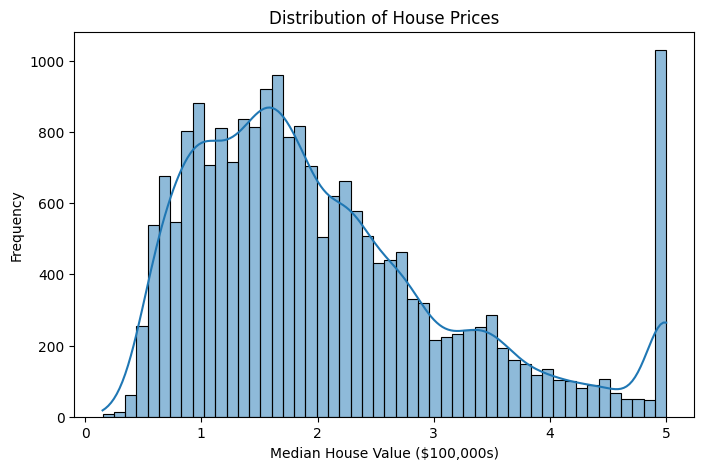

In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(df['target'], bins=50, kde=True)
plt.title('Distribution of House Prices')
plt.xlabel('Median House Value ($100,000s)')
plt.ylabel('Frequency')
plt.show()

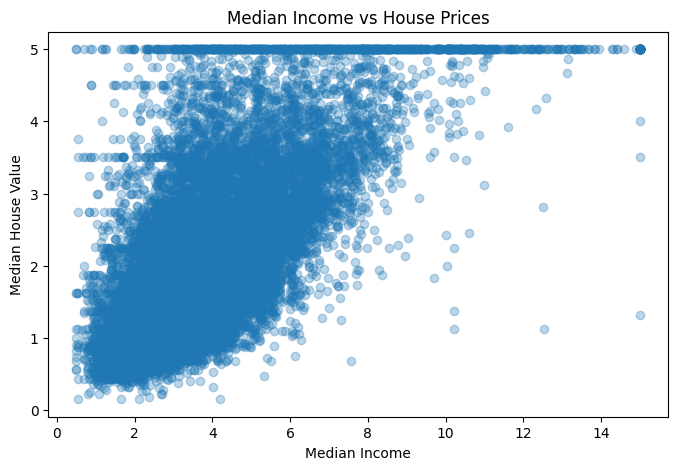

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(df['MedInc'], df['target'], alpha=0.3)
plt.xlabel('Median Income')
plt.ylabel('Median House Value')
plt.title('Median Income vs House Prices')
plt.show()

## 1. Project Overview

### California Housing Price Prediction Using Linear Regression

**Objective:** Build a Machine Learning model using Linear Regression to predict median house values based on various housing and demographic features.

We use the California Housing dataset provided by Scikit-learn.

## 2. Dataset Loading

Imported the necessary Python libraries:

- NumPy: Numerical operations.
- Pandas: Data manipulation and analysis.
- Matplotlib: Data visualization.
- Seaborn: Statistical data visualization.
- Scikit-learn: Dataset loading and Machine Learning.

Loaded the California Housing dataset using `fetch_california_housing()` and converted it into a Pandas DataFrame.

The dataset contains:
- 20,640 records.
- 8 input features.
- 1 target variable.

## 3. Initial Data Inspection

Used the following methods to understand the dataset:

- `df.head()` – Viewed the first five records.
- `df.shape` – Checked the number of rows and columns.
- `df.info()` – Examined column names, data types and non-null counts.
- `df.describe()` – Obtained statistical summaries such as mean, standard deviation, minimum, maximum and quartiles.

### Important observations

The dataset contains 20,640 records and 9 columns, including the target variable.

## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand the dataset before training the model.

### 4.1 Checking Missing Values

Used `df.isnull().sum()` to identify missing values.

**Observation:** No missing values were found in any column.

### 4.2 Checking Duplicate Records

Used `df.duplicated().sum()` to identify duplicate rows.

**Observation:** No duplicate records were found.

### 4.3 Understanding Target Distribution

Created a histogram using Seaborn's `histplot()` to understand the distribution of median house values.

**Observations:**
- Most house values are concentrated between approximately $100,000 and $250,000.
- The distribution is positively skewed, with a tail towards higher house values.
- A noticeable spike exists at $500,000 because the dataset caps the target values at this amount.

### 4.4 Median Income vs House Prices

Created a scatter plot using Matplotlib's `scatter()` function to examine the relationship between median income and median house values.

**Observations:**
- A positive relationship exists between median income and house prices.
- Areas with higher median incomes generally tend to have higher house values.
- The relationship is not perfectly linear, suggesting that other features also influence house prices.

**Conclusion:** Median income appears to be a useful feature for predicting house prices.

In [11]:
X = df.drop('target', axis=1)
y = df['target']

In [12]:
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [13]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(16512, 8)
(4128, 8)
(16512,)
(4128,)


In [15]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
print(y_pred[:10])
print(y_test[:10])


[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]
20046    0.47700
3024     0.45800
15663    5.00001
20484    2.18600
9814     2.78000
13311    1.58700
7113     1.98200
7668     1.57500
18246    3.40000
5723     4.46600
Name: target, dtype: float64


In [16]:
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score
mae=mean_absolute_error(y_test,y_pred)
print("Mean Absolute Error:",mae)
r2=r2_score(y_test,y_pred)
print("\nR2 Score:",r2)
mse = mean_squared_error(y_test, y_pred)
print("\nMean Squared Error:", mse)
rmse = np.sqrt(mse)
print("\nRoot Mean Squared Error:", rmse)

Mean Absolute Error: 0.5332001304956561

R2 Score: 0.5757877060324512

Mean Squared Error: 0.5558915986952438

Root Mean Squared Error: 0.745581383012776


## 5. Model Training and Evaluation

### 5.1 Train-Test Split

Split the dataset into training and testing sets using `train_test_split()`.

- 80% training data (16,512 records).
- 20% testing data (4,128 records).
- `random_state=42` was used to ensure reproducibility.

### 5.2 Model Training

Imported `LinearRegression` from Scikit-learn.

Created a Linear Regression model and trained it using:

`model.fit(X_train, y_train)`

The model learned the relationship between the eight input features and median house values.

### 5.3 Predictions

Used `model.predict(X_test)` to generate predictions on unseen testing data.

Compared the predicted values (`y_pred`) with actual values (`y_test`).

### 5.4 Model Evaluation

Evaluated the model using four regression metrics.

| Metric | Result |
|---|---:|
| Mean Absolute Error (MAE) | 0.5332 |
| Mean Squared Error (MSE) | 0.5559 |
| Root Mean Squared Error (RMSE) | 0.7456 |
| R² Score | 0.5758 |

**Observations:**

- MAE indicates an average absolute prediction error of approximately $53,320.
- RMSE indicates a root mean squared error of approximately $74,558.
- R² indicates that the model explains approximately 57.58% of the variation in house values.

### Conclusion

The Linear Regression model establishes a baseline for predicting California house prices. It captures some of the relationships between housing features and prices, but its performance indicates scope for further improvement.

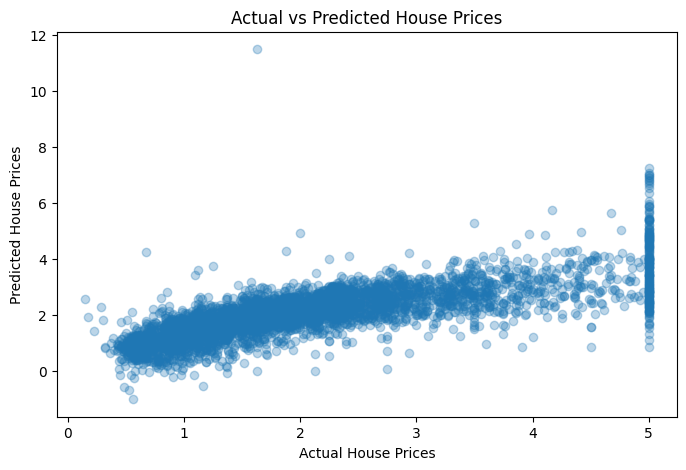

In [17]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel('Actual House Prices')
plt.ylabel('Predicted House Prices')
plt.title('Actual vs Predicted House Prices')
plt.show()

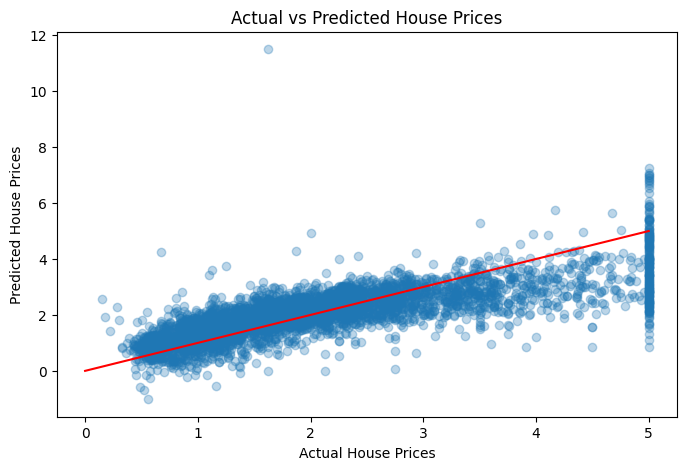

In [18]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([0, 5], [0, 5], color='red')
plt.xlabel('Actual House Prices')
plt.ylabel('Predicted House Prices')
plt.title('Actual vs Predicted House Prices')
plt.show()

In [19]:
coefficients = pd.DataFrame({'Feature': X.columns,'Coefficient': model.coef_})
print(coefficients)

      Feature  Coefficient
0      MedInc     0.448675
1    HouseAge     0.009724
2    AveRooms    -0.123323
3   AveBedrms     0.783145
4  Population    -0.000002
5    AveOccup    -0.003526
6    Latitude    -0.419792
7   Longitude    -0.433708


In [20]:
print("Intercept:", model.intercept_)

Intercept: -37.02327770606405


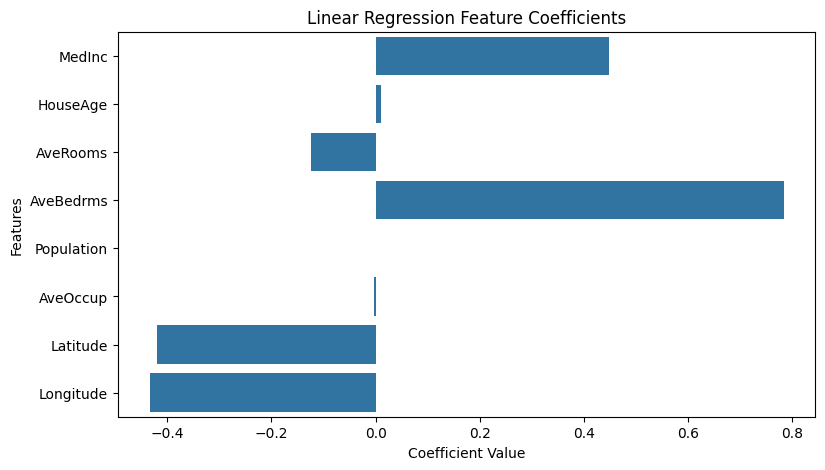

In [21]:
plt.figure(figsize=(9, 5))
sns.barplot(data=coefficients, x='Coefficient', y='Feature')
plt.title('Linear Regression Feature Coefficients')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')
plt.show()

In [22]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)
print("Original features:", X_train.shape)
print("Polynomial features:", X_train_poly.shape)
model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train)
y_pred_poly = model_poly.predict(X_test_poly)

Original features: (16512, 8)
Polynomial features: (16512, 44)


In [23]:
poly_mae = mean_absolute_error(y_test, y_pred_poly)
poly_mse = mean_squared_error(y_test, y_pred_poly)
poly_rmse = np.sqrt(poly_mse)
poly_r2 = r2_score(y_test, y_pred_poly)
print("Polynomial Regression Results")
print("MAE:", poly_mae)
print("MSE:", poly_mse)
print("RMSE:", poly_rmse)
print("R2 Score:", poly_r2)

Polynomial Regression Results
MAE: 0.4670009334741879
MSE: 0.4643015240584696
RMSE: 0.6813967449720241
R2 Score: 0.6456819727519338


In [24]:
y_train_pred_poly = model_poly.predict(X_train_poly)
train_r2 = r2_score(y_train, y_train_pred_poly)
test_r2 = r2_score(y_test, y_pred_poly)
print("Training R2:", train_r2)
print("Testing R2:", test_r2)

Training R2: 0.6852681982344969
Testing R2: 0.6456819727519338


In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)

In [26]:
ridge_mae = mean_absolute_error(y_test, y_pred_ridge)
ridge_mse = mean_squared_error(y_test, y_pred_ridge)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, y_pred_ridge)
print("Ridge Regression Results")
print("MAE:", ridge_mae)
print("MSE:", ridge_mse)
print("RMSE:", ridge_rmse)
print("R2 Score:", ridge_r2)

Ridge Regression Results
MAE: 0.48797138549477215
MSE: 0.47288331755005314
RMSE: 0.687665120207542
R2 Score: 0.6391330299149398


In [27]:
for a in [0.01, 0.1, 1, 10, 100]:
    model = Ridge(alpha=a)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    print("Alpha:", a, "| R2:", r2_score(y_test, pred))

Alpha: 0.01 | R2: 0.6665851421689056
Alpha: 0.1 | R2: 0.6599529621801363
Alpha: 1 | R2: 0.6391330299149398
Alpha: 10 | R2: 0.6192286874392479
Alpha: 100 | R2: 0.6116855107861662


## Model Improvement and Experimentation

After establishing Linear Regression as our baseline model, we experimented with Polynomial Regression and Ridge Regression to improve prediction performance.

### 1. Polynomial Regression

**Objective:** Capture nonlinear relationships between the input features and house prices.

We used `PolynomialFeatures` with `degree=2` to generate:
- Original features
- Squared features
- Pairwise interaction features

The original dataset contained 8 features. Polynomial transformation expanded these into 44 features.

We then trained a Linear Regression model using the transformed features.

**Results:**

| Metric | Value |
|---|---:|
| MAE | 0.4670 |
| MSE | 0.4643 |
| RMSE | 0.6814 |
| R² Score | 0.6457 |

The model achieved an R² score of approximately 64.57%, improving upon the baseline Linear Regression model.

**Overfitting check:**

We compared training and testing R² scores:

- Training R²: 0.6853
- Testing R²: 0.6457

The relatively small difference suggested that the model generalised reasonably well to unseen data.

### 2. Ridge Regression

**Objective:** Reduce the risk of overfitting by applying regularisation to the polynomial model.

Polynomial features can be highly correlated. Ridge Regression addresses this by adding an L2 penalty to the model's coefficients.

Before training, we applied `StandardScaler` to the polynomial features.

We fitted the scaler only on the training data and used the same transformation on the test data to prevent data leakage.

We initially trained Ridge Regression with `alpha=1.0`.

**Initial Results:**

| Metric | Value |
|---|---:|
| MAE | 0.4880 |
| MSE | 0.4729 |
| RMSE | 0.6877 |
| R² Score | 0.6391 |

The initial Ridge model performed slightly worse than Polynomial Regression.

### 3. Hyperparameter Tuning

We experimented with different values of `alpha` to understand how regularisation strength affects model performance.

| Alpha | R² Score |
|---:|---:|
| 0.01 | 0.6666 |
| 0.1 | 0.6600 |
| 1 | 0.6391 |
| 10 | 0.6192 |
| 100 | 0.6117 |

**Observation:**

The best result was obtained with `alpha=0.01`, achieving an R² score of approximately 66.66%.

As alpha increased, performance decreased. This suggests that stronger regularisation was restricting the model too much and potentially causing underfitting.

### 4. Model Comparison So Far

| Model | Best R² Score |
|---|---:|
| Linear Regression | 0.5758 |
| Polynomial Regression | 0.6457 |
| Ridge Regression | **0.6666** |

**Conclusion:**

Ridge Regression with `alpha=0.01` currently gives the best test-set performance among the three experiments.

Polynomial feature expansion helped capture nonlinear patterns, while Ridge regularisation improved the model further by controlling coefficient magnitudes.

Further experiments will involve Random Forest Regression, followed by a final comparison of the models.

In [29]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [30]:
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_mse = mean_squared_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, y_pred_rf)
print("Random Forest Results")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Results
MAE: 0.3275425684593025
MSE: 0.2553684927247781
RMSE: 0.5053399773665033
R2 Score: 0.8051230593157366


In [31]:
y_train_pred_rf = rf_model.predict(X_train)
train_r2_rf = r2_score(y_train, y_train_pred_rf)
test_r2_rf = r2_score(y_test, y_pred_rf)
print("Training R2:", train_r2_rf)
print("Testing R2:", test_r2_rf)

Training R2: 0.9735726320302575
Testing R2: 0.8051230593157366


In [32]:
rf_model_2 = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42,n_jobs=-1)
rf_model_2.fit(X_train, y_train)
y_pred_rf_2 = rf_model_2.predict(X_test)
y_train_pred_rf_2 = rf_model_2.predict(X_train)
print("Training R2:", r2_score(y_train, y_train_pred_rf_2))
print("Testing R2:", r2_score(y_test, y_pred_rf_2))

Training R2: 0.9567164152114612
Testing R2: 0.800365851772264


In [33]:
rf_model_3 = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf_model_3.fit(X_train, y_train)
y_pred_rf_3 = rf_model_3.predict(X_test)
y_train_pred_rf_3 = rf_model_3.predict(X_train)
print("Training R2:", r2_score(y_train, y_train_pred_rf_3))
print("Testing R2:", r2_score(y_test, y_pred_rf_3))

Training R2: 0.9073920540625899
Testing R2: 0.7973631726047992


In [34]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score( rf_model, X_train, y_train, cv=5, scoring='r2', n_jobs=-1)
print("CV Scores:", cv_scores)
print("Average CV R2:", cv_scores.mean())

CV Scores: [0.80899315 0.79381357 0.80828862 0.80440441 0.8051215 ]
Average CV R2: 0.8041242497453812


In [35]:
importance = rf_model.feature_importances_
feature_importance = pd.DataFrame({ 'Feature': X.columns, 'Importance': importance})
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)
print(feature_importance)

      Feature  Importance
0      MedInc    0.524871
5    AveOccup    0.138443
6    Latitude    0.088936
7   Longitude    0.088629
1    HouseAge    0.054593
2    AveRooms    0.044272
4  Population    0.030650
3   AveBedrms    0.029606


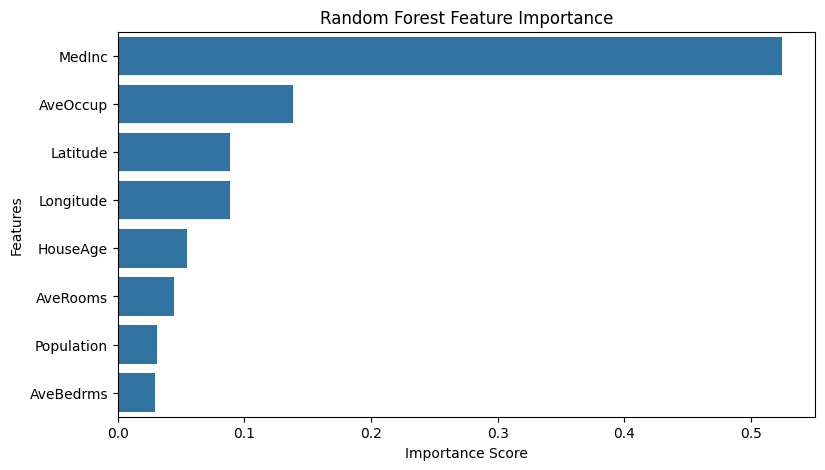

In [36]:
plt.figure(figsize=(9, 5))
sns.barplot( data=feature_importance, x='Importance', y='Feature')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

In [37]:
model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Polynomial Regression', 'Ridge Regression', 'Random Forest'],
    'R2 Score': [ 0.5758, 0.6457, 0.6666, 0.8051],
    'MAE': [ 0.5332, 0.4670, 0.4880, 0.3275]
})

model_comparison

,Model,R2 Score,MAE
0,Linear Regression,0.5758,0.5332
1,Polynomial Regression,0.6457,0.4670
2,Ridge Regression,0.6666,0.4880
3,Random Forest,0.8051,0.3275


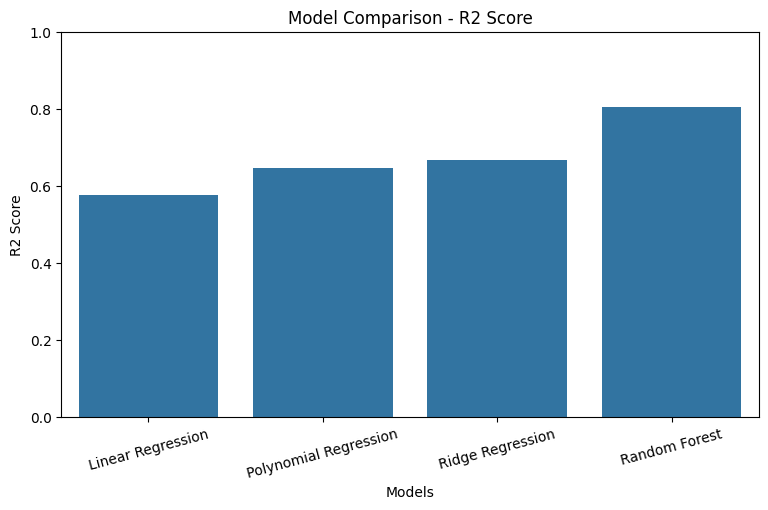

In [38]:
plt.figure(figsize=(9, 5))
sns.barplot(data=model_comparison, x='Model', y='R2 Score')
plt.title('Model Comparison - R2 Score')
plt.xlabel('Models')
plt.ylabel('R2 Score')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

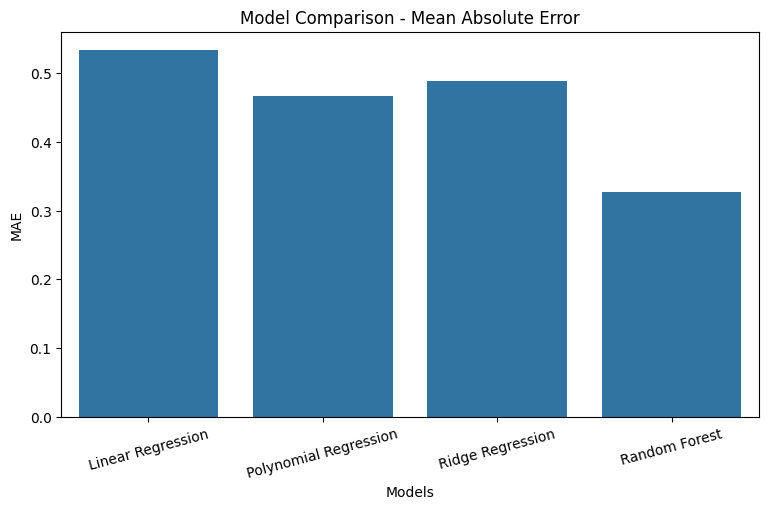

In [39]:
plt.figure(figsize=(9, 5))
sns.barplot(data=model_comparison, x='Model', y='MAE')
plt.title('Model Comparison - Mean Absolute Error')
plt.xlabel('Models')
plt.ylabel('MAE')
plt.xticks(rotation=15)
plt.show()

## 5. Random Forest Regression

**Objective:** Improve prediction performance by using an ensemble of decision trees capable of capturing complex nonlinear relationships.

We implemented `RandomForestRegressor` using the original eight input features without polynomial transformation or feature scaling.

The initial model was configured with 100 decision trees.

### Initial Model Results

| Metric | Value |
|---|---:|
| MAE | 0.3275 |
| MSE | 0.2554 |
| RMSE | 0.5053 |
| R² Score | 0.8051 |

The model achieved an R² score of approximately 80.51%, significantly outperforming the previous regression models.

### Overfitting Analysis

We compared training and testing performance.

- Training R²: 0.9736
- Testing R²: 0.8051

The difference indicated potential overfitting.

### Controlling Model Complexity

We experimented with two additional configurations.

**Experiment 1: Limiting tree depth**

We set `max_depth=15` to restrict the maximum depth of individual decision trees.

- Training R²: 0.9567
- Testing R²: 0.8004

**Experiment 2: Increasing minimum leaf samples**

We added `min_samples_leaf=5`, requiring each leaf to contain at least five training samples.

- Training R²: 0.9074
- Testing R²: 0.7974

These experiments reduced the training-testing performance gap, but also slightly reduced test performance. Therefore, the original Random Forest remained our best-performing configuration.

### Cross-Validation

To assess the consistency of the original Random Forest, we performed 5-Fold Cross-Validation on the training dataset using R² as the evaluation metric.

| Fold | R² Score |
|---|---:|
| 1 | 0.8090 |
| 2 | 0.7938 |
| 3 | 0.8083 |
| 4 | 0.8044 |
| 5 | 0.8051 |

**Average Cross-Validation R²: 0.8041 (80.41%)**

The average cross-validation score was very close to the test-set R² of 80.51%, suggesting consistent performance across different validation subsets.

### Feature Importance

We extracted the feature importance values from the trained Random Forest model.

| Feature | Importance |
|---|---:|
| MedInc | 0.5249 |
| AveOccup | 0.1384 |
| Latitude | 0.0889 |
| Longitude | 0.0886 |
| HouseAge | 0.0546 |
| AveRooms | 0.0443 |
| Population | 0.0307 |
| AveBedrms | 0.0296 |

Median income (`MedInc`) was the most influential feature, accounting for approximately 52.49% of the model's total feature importance.

This indicates that median income played a major role in the model's predictions. Feature importance does not establish a causal relationship.

### Conclusion

Random Forest Regression achieved the best performance among the models tested, with an R² score of 80.51% and an MAE of 0.3275.

Five-fold cross-validation produced an average R² of 80.41%, providing additional evidence of consistent model performance.

Further validation and hyperparameter tuning can help improve the reliability and generalisation of the model.

## 6. Model Comparison and Visualization

After training and evaluating all four regression models, their performance was compared using **R² Score** and **Mean Absolute Error (MAE)**.

### 6.1 Model Performance Comparison

The following table summarizes the evaluation results:

| Model | R² Score | MAE |
|---|---:|---:|
| Linear Regression | 0.5758 | 0.5332 |
| Polynomial Regression | 0.6457 | 0.4670 |
| Ridge Regression | 0.6666 | 0.4880 |
| Random Forest | **0.8051** | **0.3275** |

### 6.2 R² Score Comparison

A bar plot was created to compare the R² scores of all four models.

- A higher R² score indicates that the model explains a greater proportion of the variance in the target variable.
- Random Forest achieved the highest R² score of approximately **80.51%**.
- Linear Regression achieved the lowest R² score of approximately **57.58%**.

### 6.3 MAE Comparison

A second bar plot was created to compare the Mean Absolute Error (MAE) of the models.

- MAE measures the average absolute difference between actual and predicted values.
- A lower MAE indicates better prediction performance.
- Random Forest achieved the lowest MAE of approximately **0.3275**, making it the best-performing model according to this metric.

### 6.4 Final Observation

Based on the evaluation results, Random Forest Regression performed better than Linear Regression, Polynomial Regression, and Ridge Regression.

It achieved the highest R² score and the lowest MAE among the four models. This suggests that it was better able to capture the nonlinear relationships and complex patterns in the California Housing dataset.

However, the Random Forest model also showed a noticeable difference between its training and testing R² scores, indicating some overfitting.

**Conclusion:** Random Forest Regression was the best-performing model in this experiment, with a test R² score of approximately 80.51% and an MAE of 0.3275.